# LDA Comparison

**Cross-notebook comparison of all four LDA configurations.**

*Run all four LDA notebooks end-to-end before this notebook so that their variables and outputs are available.*

## 1. Methodology recap

Four flat-LDA configurations are compared in a 2×2 design: **inference algorithm** (gensim VB vs tomotopy CGS) × **document granularity** (page vs deck).

| Notebook | Library | Inference | Granularity | Split | Best K |
|----------|---------|-----------|-------------|-------|--------|
| `lda-page-cgs` | tomotopy | CGS | Page | 108/13 (90/10) | **8** |
| `lda-page-vb` | gensim | VB | Page | 108/13 (90/10) | **3** |
| `lda-deck-cgs` | tomotopy | CGS | Deck | 8/1 (LOO) | **3** |
| `lda-deck-vb` | gensim | VB | Deck | 8/1 (LOO) | **3** |

**Train/test split:** all four notebooks use a deterministic holdout split (`random_state=42`). Page-level notebooks: 108 train / 13 test pages. Deck-level notebooks: leave-one-out (8 train / 1 test). Each notebook trains exclusively on its training partition and reports both in-sample and holdout perplexity.

**Metrics reported:**
- **C_v coherence** — higher is better; computed with each library's native estimator (values not directly comparable across libraries — see Section 7 for a common-estimator cross-check);
- **U_mass coherence** — higher (closer to 0) is better; not strictly comparable across libraries;
- **in-sample perplexity** — lower is better; tomotopy uses `exp(-ll_per_word)`, gensim uses `exp(-log_perplexity)`, both on the same scale;
- **holdout perplexity** — lower is better; tomotopy via `model.infer()`, gensim via inferred θ scored as P(w|θ,φ); **VB holdout perplexity uses a variational bound and is not interpretable in absolute value** (marked †);
- **topic diversity** (Dieng et al. 2020) — unique words across top-25 / K×25; higher is better;
- **mean pairwise cosine similarity** — lower = more distinct topics;
- **mean Shannon entropy** — higher = more spread-out document-topic distributions;
- **exclusivity** (mean P(topic|word) over top-10) — higher = words concentrated in that topic.

In [27]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_nb_dir = os.path.dirname(os.path.abspath('lda_comparison.ipynb'))
_src_dir = os.path.abspath(os.path.join(_nb_dir, '..'))
if _src_dir not in sys.path:
    sys.path.insert(0, _src_dir)
from utils import OUTPUT_ROOT

plt.rcParams.update({
    'figure.dpi'       : 130,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.titlesize'   : 12,
    'axes.labelsize'   : 10,
    'font.family'      : 'serif',
})

In [28]:
# ── Static comparison table — values sourced from each notebook's summary cell ─
# VB test perplexity marked † (variational bound, not interpretable in absolute value).

RESULTS = {
    'Notebook':            ['page-cgs (k=8)', 'page-vb (k=3)', 'deck-cgs (k=3)', 'deck-vb (k=3)'],
    'Library':             ['tomotopy',        'gensim',         'tomotopy',        'gensim'],
    'Inference':           ['CGS',             'VB',             'CGS',             'VB'],
    'Granularity':         ['page',            'page',           'deck',            'deck'],
    'K':                   [8,                 3,                3,                 3],
    'C_v':                 [0.80,              0.44,             0.65,              0.42],
    'U_mass':              [-8.09,             -11.62,           -0.45,             -0.86],
    'Train Perplexity':    [429.04,            990.49,           417.16,            560.03],
    'Test Perplexity':     ['11.56',           '6.28e+09 (\u2020)',   '13.62',           '1.79e+17 (\u2020)'],
    'Diversity (top-25)':  [0.94,              0.80,             1.00,              0.83],
    'Cosine Sim (mean)':   [0.007,             0.174,            0.000,             0.053],
    'Shannon Entropy':     [3.80,              5.13,             4.35,              4.84],
    'Exclusivity (top-10)':[0.91,              0.63,             0.99,              0.73],
}

comp_df = pd.DataFrame(RESULTS).set_index('Notebook')

CV_THRESHOLD = 0.50

def _highlight_cv(val):
    if not isinstance(val, (int, float)):
        return ''
    if val >= CV_THRESHOLD:
        return 'background-color: #e8f5e9; color: #1b5e20; font-weight: bold'
    return 'background-color: #ffebee; color: #b71c1c; font-weight: bold'

HIGHER_IS_BETTER = {
    'C_v': True, 'U_mass': True,
    'Train Perplexity': False,
    'Diversity (top-25)': True,
    'Cosine Sim (mean)': False,
    'Shannon Entropy': False,
    'Exclusivity (top-10)': True,
}

def _highlight_best_worst_col(s):
    styles = [''] * len(s)
    if s.name not in HIGHER_IS_BETTER:
        return styles
    vals = pd.to_numeric(s, errors='coerce')
    if vals.isna().all():
        return styles
    higher = HIGHER_IS_BETTER[s.name]
    best_idx  = vals.idxmax() if higher else vals.idxmin()
    worst_idx = vals.idxmin() if higher else vals.idxmax()
    pos = list(s.index)
    styles[pos.index(best_idx)]  = 'background-color: #e8f5e9; color: #1b5e20; font-weight: bold'
    styles[pos.index(worst_idx)] = 'background-color: #ffebee; color: #b71c1c; font-weight: bold'
    return styles

fmt = {
    'C_v':                  '{:.2f}',
    'U_mass':               '{:.2f}',
    'Train Perplexity':     '{:.2f}',
    'Diversity (top-25)':   '{:.2f}',
    'Cosine Sim (mean)':    '{:.3f}',
    'Shannon Entropy':      '{:.2f}',
    'Exclusivity (top-10)': '{:.2f}',
}

comp_df.style.format(fmt).map(
    _highlight_cv, subset=['C_v']
).apply(
    _highlight_best_worst_col,
    subset=['U_mass', 'Train Perplexity', 'Diversity (top-25)',
            'Cosine Sim (mean)', 'Shannon Entropy', 'Exclusivity (top-10)']
).set_caption(
    'LDA 2\u00d72 comparison \u2014 best K per notebook  '
    '(C_v \u2265 0.50 = green, < 0.50 = red; per-metric best = green, worst = red)  '
    '(\u2020 VB test perplexity = variational bound, not interpretable in absolute value)'
)

,Library,Inference,Granularity,K,C_v,U_mass,Train Perplexity,Test Perplexity,Diversity (top-25),Cosine Sim (mean),Shannon Entropy,Exclusivity (top-10)
Notebook,,,,,,,,,,,,
page-cgs (k=8),tomotopy,CGS,page,8,0.80,-8.09,429.04,11.56,0.94,0.007,3.80,0.91
page-vb (k=3),gensim,VB,page,3,0.44,-11.62,990.49,6.28e+09 (†),0.80,0.174,5.13,0.63
deck-cgs (k=3),tomotopy,CGS,deck,3,0.65,-0.45,417.16,13.62,1.00,0.000,4.35,0.99
deck-vb (k=3),gensim,VB,deck,3,0.42,-0.86,560.03,1.79e+17 (†),0.83,0.053,4.84,0.73


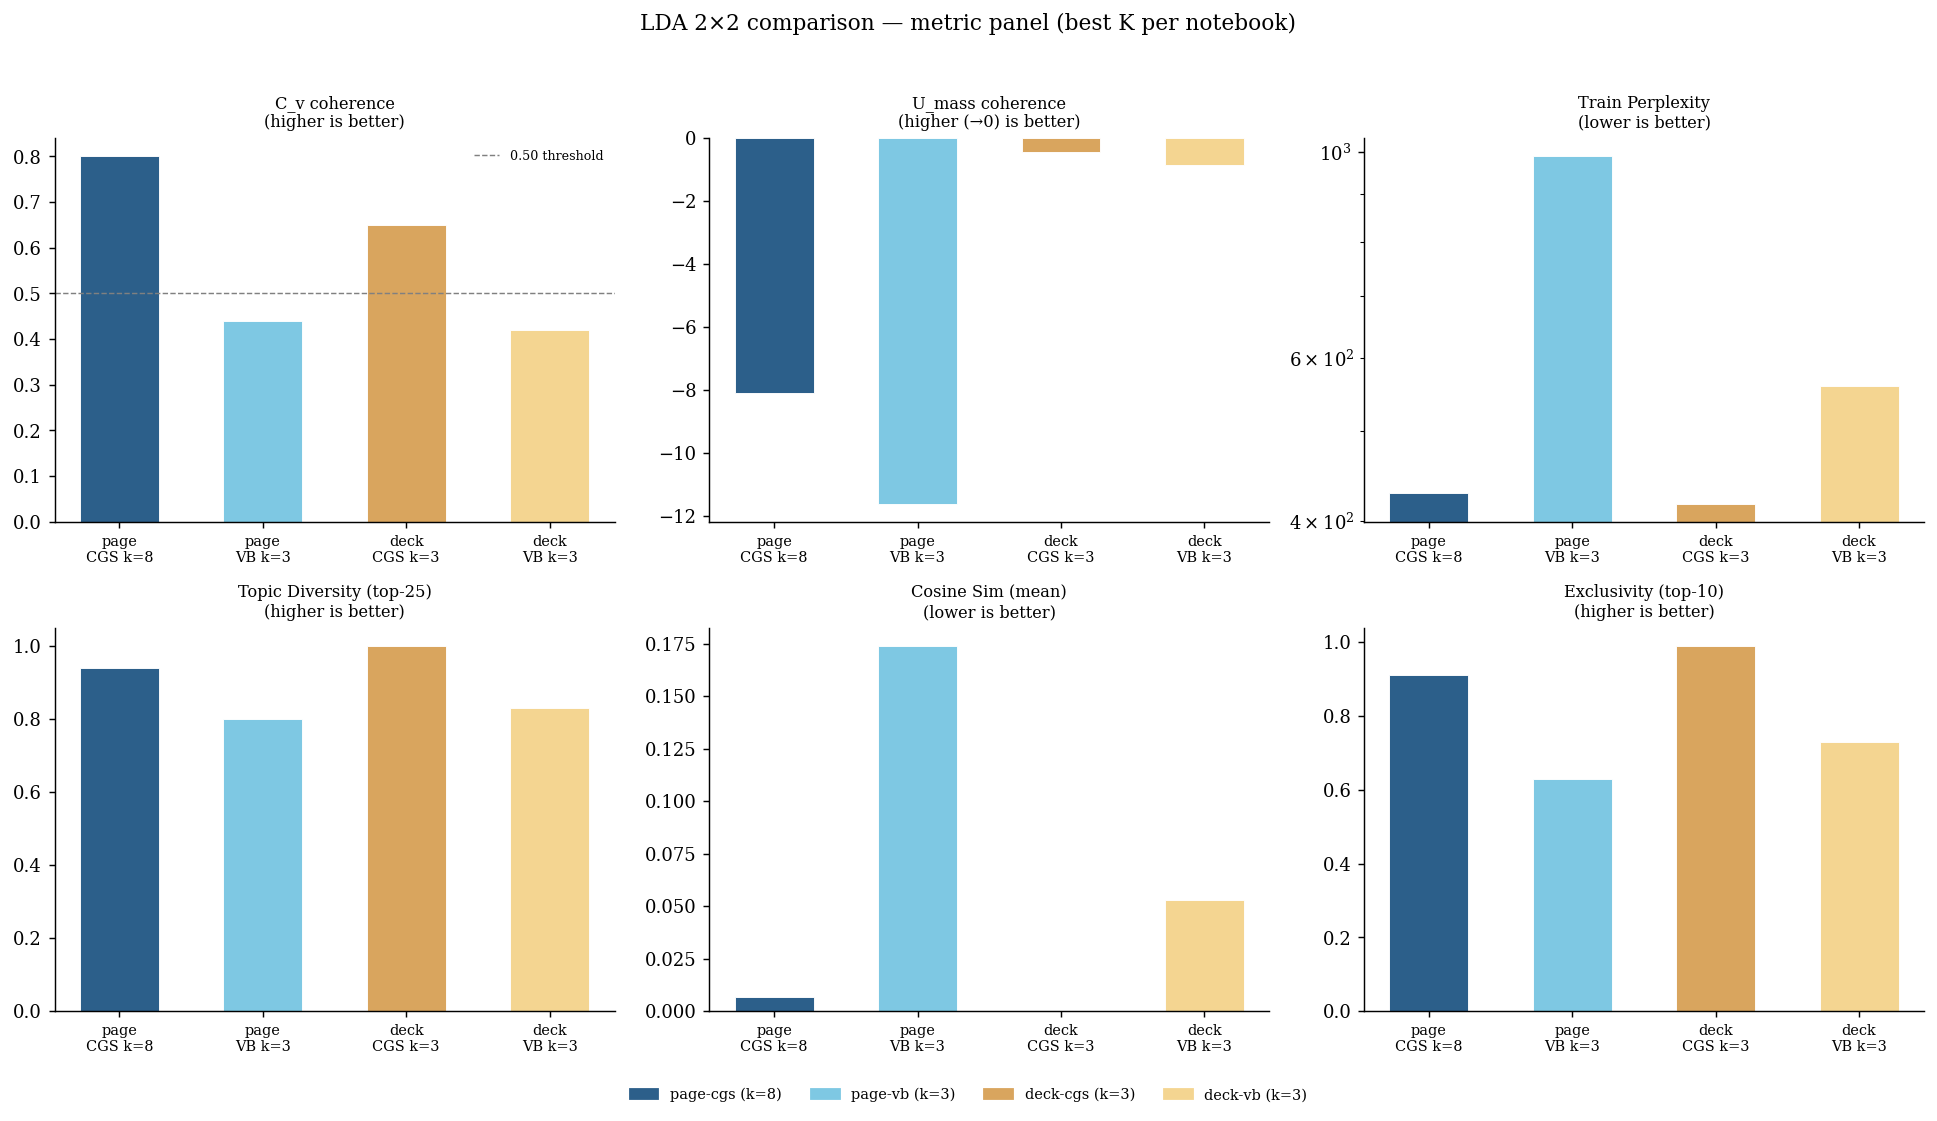

Figure saved.


In [29]:
import matplotlib.patches as mpatches

NOTEBOOKS  = ['page-cgs (k=8)', 'page-vb (k=3)', 'deck-cgs (k=3)', 'deck-vb (k=3)']
COLORS     = ['#2C5F8A', '#7EC8E3', '#D9A55E', '#F4D591']   # CGS page, VB page, CGS deck, VB deck

metrics_panel = [
    ('C_v',                 'C_v coherence',            'higher is better', False),
    ('U_mass',              'U_mass coherence',          'higher (→0) is better', False),
    ('Train Perplexity',    'Train Perplexity',          'lower is better',  True),
    ('Diversity (top-25)',  'Topic Diversity (top-25)',  'higher is better', False),
    ('Cosine Sim (mean)',   'Cosine Sim (mean)',         'lower is better',  False),
    ('Exclusivity (top-10)','Exclusivity (top-10)',      'higher is better', False),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
x = np.arange(len(NOTEBOOKS))
width = 0.55

for ax, (metric, title, direction, log_y) in zip(axes, metrics_panel):
    vals = [RESULTS[metric][i] for i in range(4)]
    numeric_vals = []
    bar_colors = []
    for v, c in zip(vals, COLORS):
        try:
            numeric_vals.append(float(str(v).replace(' (†)', '')))
            bar_colors.append(c)
        except ValueError:
            numeric_vals.append(0)
            bar_colors.append('#cccccc')
    ax.bar(x, numeric_vals, width, color=bar_colors, edgecolor='white', linewidth=0.5)
    ax.set_xticks(x)
    ax.set_xticklabels(['page\nCGS k=8', 'page\nVB k=3', 'deck\nCGS k=3', 'deck\nVB k=3'],
                        fontsize=8)
    ax.set_title(f'{title}\n({direction})', fontsize=9)
    if log_y:
        ax.set_yscale('log')
    if metric == 'C_v':
        ax.axhline(0.50, color='gray', linestyle='--', linewidth=0.8, label='0.50 threshold')
        ax.legend(fontsize=7, frameon=False)

legend_handles = [mpatches.Patch(color=COLORS[i], label=NOTEBOOKS[i]) for i in range(4)]
fig.legend(handles=legend_handles, loc='lower center', ncol=4, fontsize=8,
           frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('LDA 2×2 comparison — metric panel (best K per notebook)', y=1.02, fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, 'lda_comparison_panel.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved.')

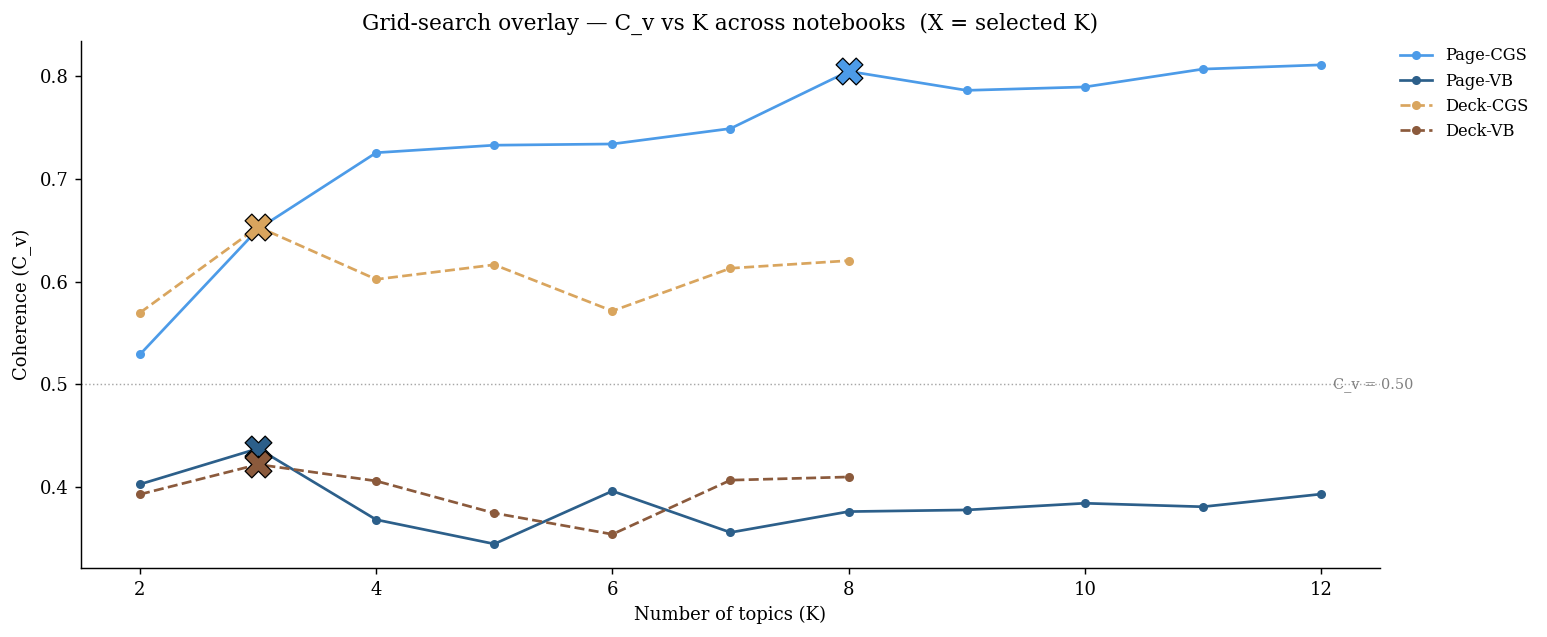

In [38]:
# ── Grid-search overlay: C_v vs K across all four notebooks ───────────────────
# Values sourced directly from each notebook's grid-search output cells.
# X marker = selected best K per notebook.

GRID_DATA = {
    'page-cgs': {
        'ks':     list(range(2, 13)),
        'cvs':    [0.5292, 0.6513, 0.7256, 0.7329, 0.7341, 0.7491,
                   0.8049, 0.7863, 0.7896, 0.8070, 0.8111],
        'best_k': 8,
        'label':  'Page-CGS',
        'style':  '-',
        'color':  '#4C9BE8',
    },
    'page-vb': {
        'ks':     list(range(2, 13)),
        'cvs':    [0.4028, 0.4376, 0.3683, 0.3447, 0.3962, 0.3559,
                   0.3762, 0.3778, 0.3843, 0.3809, 0.3932],
        'best_k': 3,
        'label':  'Page-VB',
        'style':  '-',
        'color':  '#2C5F8A',
    },
    'deck-cgs': {
        'ks':     list(range(2, 9)),
        'cvs':    [0.5698, 0.6534, 0.6023, 0.6165, 0.5715, 0.6131, 0.6205],
        'best_k': 3,
        'label':  'Deck-CGS',
        'style':  '--',
        'color':  '#D9A55E',
    },
    'deck-vb': {
        'ks':     list(range(2, 9)),
        'cvs':    [0.3930, 0.4221, 0.4060, 0.3747, 0.3541, 0.4068, 0.4099],
        'best_k': 3,
        'label':  'Deck-VB',
        'style':  '--',
        'color':  '#8B5A3C',
    },
}

fig, ax = plt.subplots(figsize=(12, 5))

for key, d in GRID_DATA.items():
    ax.plot(d['ks'], d['cvs'], linestyle=d['style'], marker='o', markersize=4,
            linewidth=1.5, color=d['color'], label=d['label'])
    best_cv = d['cvs'][d['ks'].index(d['best_k'])]
    ax.scatter([d['best_k']], [best_cv], marker='X', s=220,
               color=d['color'], edgecolor='black', linewidth=0.7, zorder=5)

ax.axhline(0.50, color='gray', linestyle=':', linewidth=0.8, alpha=0.7)
ax.text(12.1, 0.50, 'C_v = 0.50', ha='left', va='center', fontsize=8, color='gray')
ax.set_xlabel('Number of topics (K)')
ax.set_ylabel('Coherence (C_v)')
ax.set_title('Grid-search overlay — C_v vs K across notebooks  (X = selected K)')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1.0),
          fontsize=9, frameon=False, borderaxespad=0)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, 'lda_comparison_grid_overlay.png'),
            dpi=150, bbox_inches='tight')
plt.show()

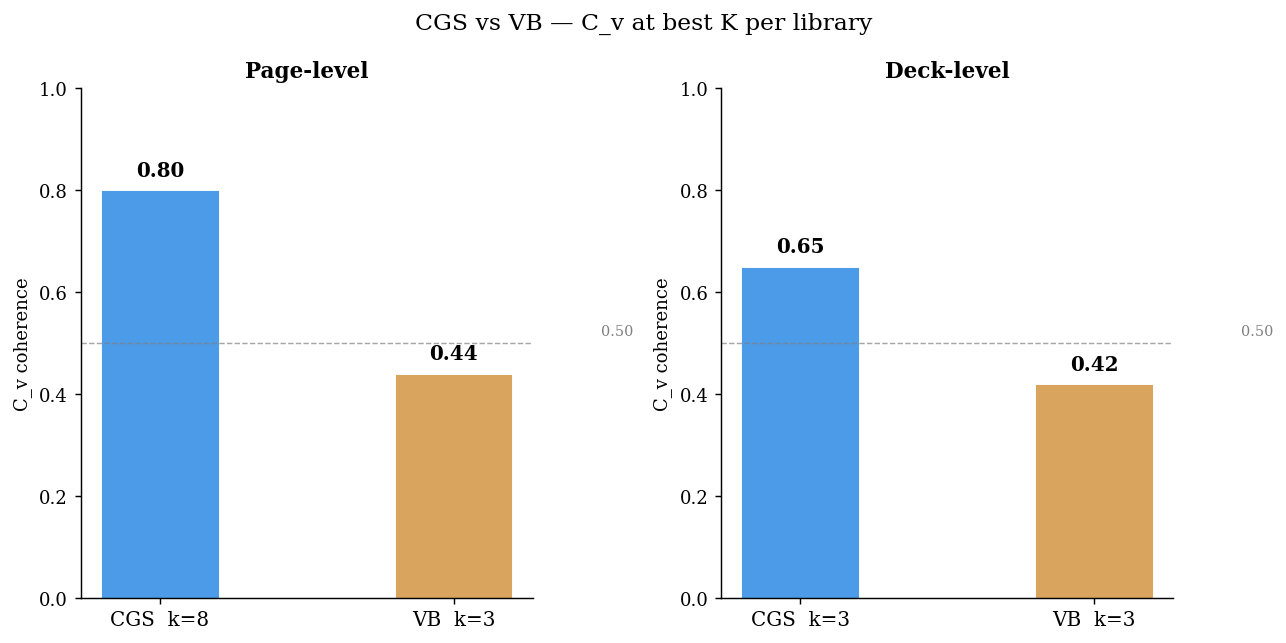

In [41]:
# ── CGS vs VB — C_v comparison at best K, page-level and deck-level ───────────

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=False)
fig.suptitle('CGS vs VB — C_v at best K per library', fontsize=13)

CGS_COLOR = '#4C9BE8'
VB_COLOR  = '#D9A55E'
w = 0.4

for ax, (title, cgs_label, vb_label, cgs_cv, vb_cv) in zip(axes, [
    ('Page-level', 'CGS  k=8', 'VB  k=3', 0.80, 0.44),
    ('Deck-level', 'CGS  k=3', 'VB  k=3', 0.65, 0.42),
]):
    bars = ax.bar([0, 1], [cgs_cv, vb_cv], width=w,
                  color=[CGS_COLOR, VB_COLOR], edgecolor='white', linewidth=0.5)
    ax.set_xticks([0, 1])
    ax.set_xticklabels([cgs_label, vb_label], fontsize=11)
    ax.set_ylabel('C_v coherence', fontsize=10)
    ax.set_ylim(0, 1.0)
    ax.axhline(0.50, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
    ax.text(1.5, 0.51, '0.50', ha='left', va='bottom', fontsize=8, color='gray')
    ax.set_title(title, fontsize=12, fontweight='bold')
    # value labels on bars
    for bar, val in zip(bars, [cgs_cv, vb_cv]):
        ax.text(bar.get_x() + bar.get_width() / 2, val + 0.02,
                f'{val:.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, 'lda_cgs_vs_vb_cv.png'), dpi=150, bbox_inches='tight')
plt.show()

## 3. Recommendation

Across the four configurations, **`lda-page-cgs` (tomotopy CGS, page-level, K=8)** is the primary flat-LDA baseline for hLDA comparison.

Selection rationale (all criteria point to the same model):

| Criterion | page-cgs k=8 | page-vb k=3 | deck-cgs k=3 | deck-vb k=3 |
|-----------|:---:|:---:|:---:|:---:|
| C_v ≥ 0.50? | **0.80 ✓** | 0.44 ✗ | 0.65 ✓ | 0.42 ✗ |
| Train perplexity | **429** | 990 | 417 | 560 |
| Test perplexity | **11.56** | n/a† | 13.62 | n/a† |
| Exclusivity | **0.91** | 0.63 | 0.99 | 0.73 |
| Granularity | **page** ← matches hLDA | page | deck ✗ | deck ✗ |

The hLDA comparison must be page-level (same granularity and same inference engine — tomotopy CGS). Deck-level results are exploratory and not load-bearing evidence for RQ2.

**Inference algorithm dominates:** CGS consistently outperforms VB on C_v and perplexity across both granularities. This is confirmed by the common-estimator check in Section 7, which rules out estimator bias as the cause.

## 4. Trade-offs and Limitations

- **Small corpus.** 108 training pages (page-level) and 8 decks (deck-level) are below the typical sweet spot for LDA. Treat absolute metric values with caution; rely on relative ordering.
- **VB holdout perplexity is non-interpretable.** gensim's `log_perplexity` on unseen documents uses the variational lower bound from training, producing astronomically large values (6.28×10⁹ for page-level, 1.79×10¹⁷ for deck-level). These are marked † and excluded from cross-model comparisons.
- **C_v estimator dependency.** Native C_v values (tomotopy vs gensim) use different implementations and are not directly comparable. Section 7 recomputes all models under a single gensim `CoherenceModel` estimator to verify CGS > VB direction.
- **U_mass cross-library.** gensim and tomotopy differ in log-zero handling for U_mass. Use ΔU_mass within one library; do not compare U_mass across libraries.
- **Deck-level extremes.** deck-cgs reports diversity=1.00 and cosine=0.000 — a mathematical consequence of 3 topics on 8 training documents: the top-10 word sets of each topic are fully disjoint. This is an artefact of the very small deck-level corpus, not a modelling error.
- **Deck-level results are exploratory** and should not be cited as load-bearing evidence for RQ2. All hLDA comparisons use the page-level baseline.

## 5. Topic-distribution heatmap across documents

Visualises how each topic is distributed across all documents for each of the four LDA configurations. Models in this section are trained on the **full corpus** (121 pages / 9 decks) for visualisation purposes only — evaluation metrics in Section 2 use the held-out split from each notebook.

**Page-level models:** stacked area chart, one column per slide page (121 docs), grouped by lecture deck. **Deck-level models:** stacked bar chart, one bar per lecture deck (9 docs).

In [40]:
import warnings
import gensim
import tomotopy as tp
from gensim import corpora
from gensim.models import LdaModel

from utils import (
    load_corpus, tokenize_corpus,
    build_slide_page_docs, build_slide_deck_docs,
    generate_topic_labels_llm,
)

warnings.filterwarnings('ignore')

RANDOM_SEED = 42
MIN_TOKENS  = 10

corpus_raw = tokenize_corpus(load_corpus())

page_docs  = build_slide_page_docs(corpus_raw)
page_docs  = page_docs[page_docs['n_tokens'] >= MIN_TOKENS].reset_index(drop=True)
deck_docs  = build_slide_deck_docs(corpus_raw)

page_texts = page_docs['tokens'].tolist()
deck_texts = deck_docs['tokens'].tolist()

def _gensim_bow(texts, min_no=2):
    d = corpora.Dictionary(texts)
    d.filter_extremes(no_below=min_no, no_above=1.0)
    return d, [d.doc2bow(t) for t in texts]

# page-vb: gensim VB / page-level / k=3 (OWN_BEST)
d1, bow1 = _gensim_bow(page_texts)
m_page_vb = LdaModel(
    corpus=bow1, id2word=d1, num_topics=3,
    passes=20, iterations=400, alpha=0.1, eta=0.01,
    random_state=RANDOM_SEED,
)

# page-cgs: tomotopy CGS / page-level / k=8 (OWN_BEST)
m_page_cgs = tp.LDAModel(k=8, alpha=0.1, eta=0.01, min_df=2, rm_top=0, seed=RANDOM_SEED)
for t in page_texts:
    m_page_cgs.add_doc(t)
m_page_cgs.train(0)
m_page_cgs.train(1000, workers=1)

# deck-vb: gensim VB / deck-level / k=3
d3, bow3 = _gensim_bow(deck_texts, min_no=1)
m_deck_vb = LdaModel(
    corpus=bow3, id2word=d3, num_topics=3,
    passes=30, iterations=500, alpha=0.1, eta=0.01,
    random_state=RANDOM_SEED,
)

# deck-cgs: tomotopy CGS / deck-level / k=3
m_deck_cgs = tp.LDAModel(k=3, alpha=0.1, eta=0.01, min_df=2, rm_top=0, seed=RANDOM_SEED)
for t in deck_texts:
    m_deck_cgs.add_doc(t)
m_deck_cgs.train(0)
m_deck_cgs.train(2000, workers=1)

print('All four models trained (full corpus, visualisation only).')

Dropping 6 empty pages after tokenisation.


All four models trained (full corpus, visualisation only).


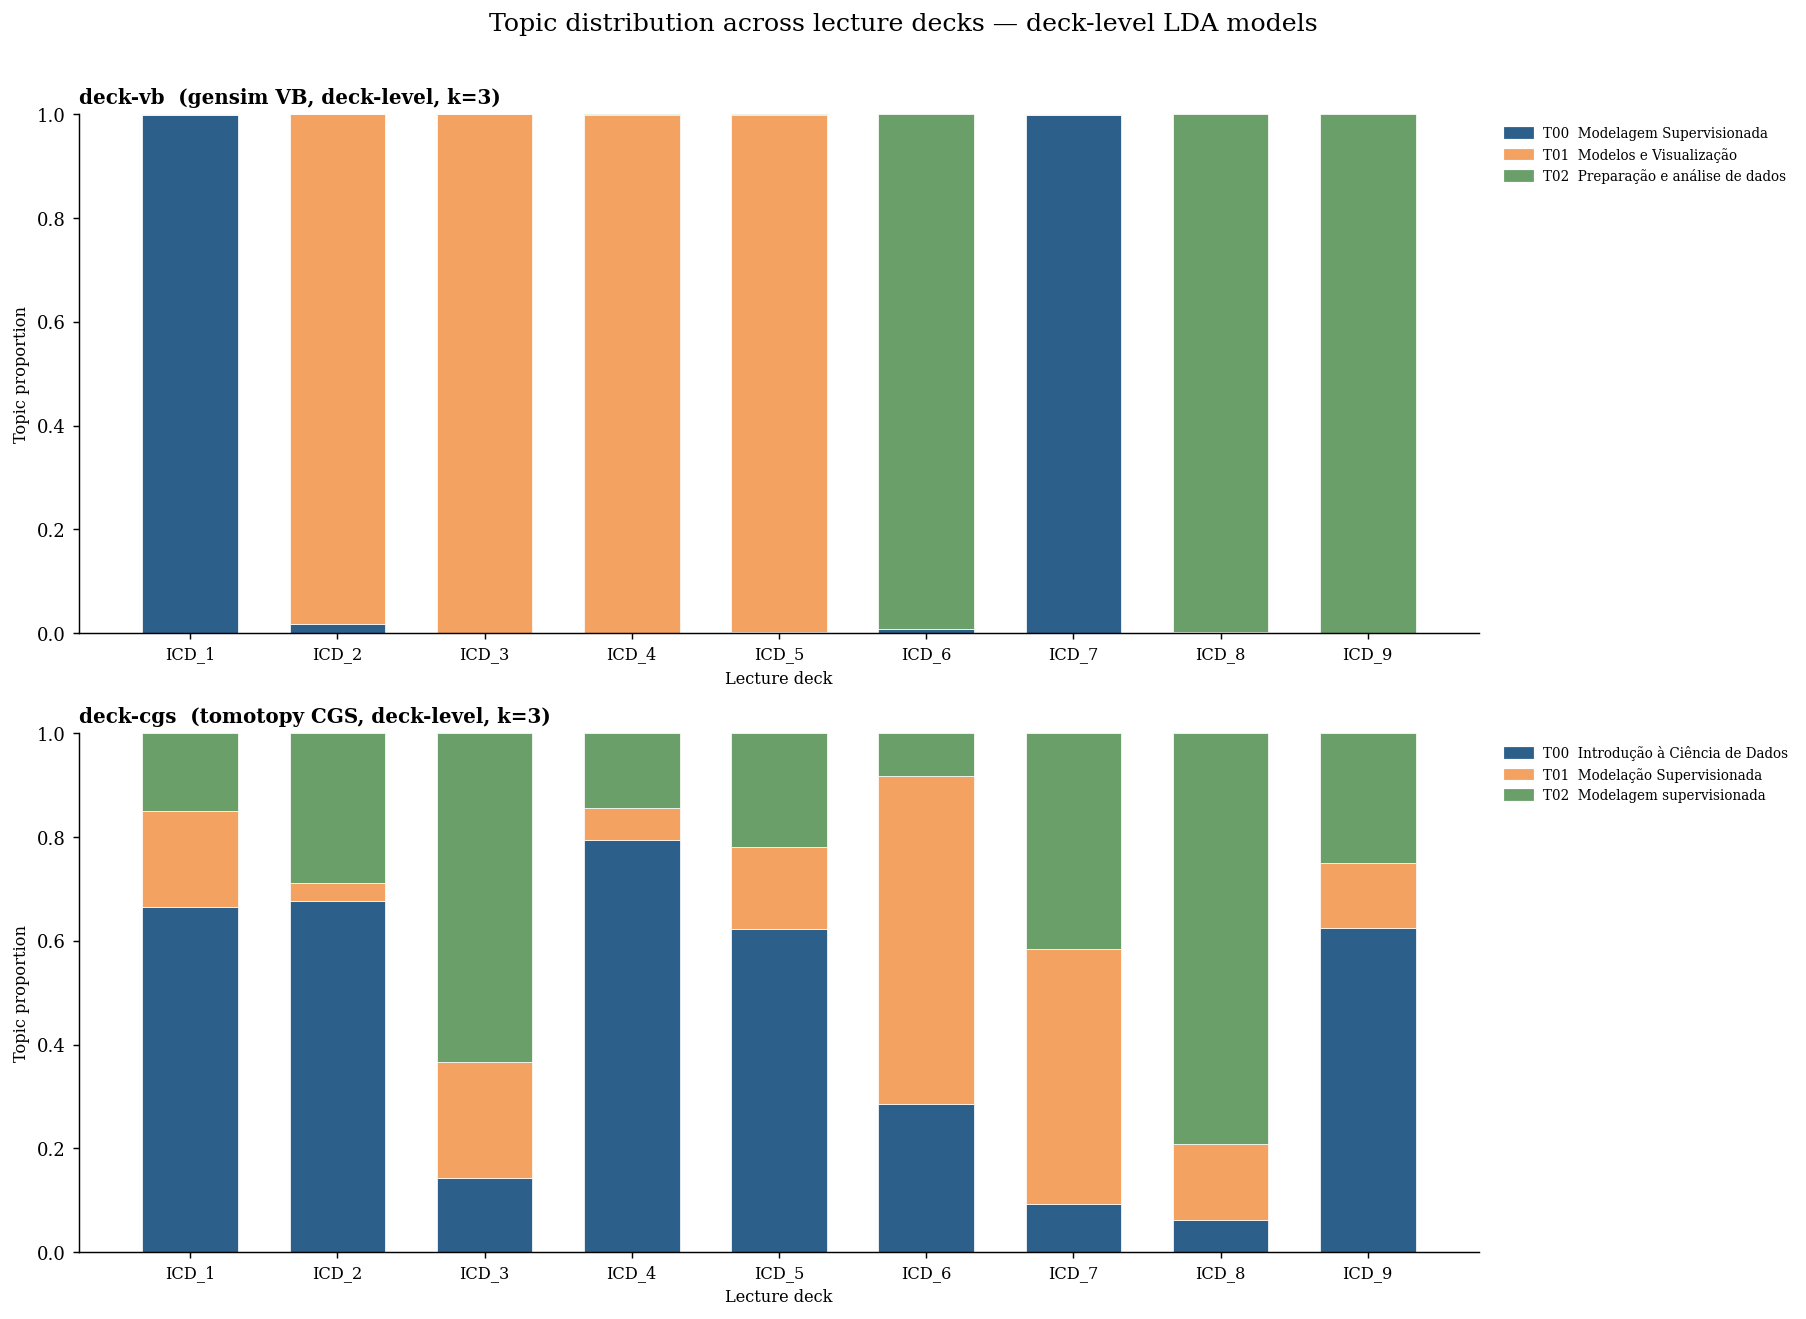

Saved to data/output/topic_distribution_deck_models.png


In [32]:
import matplotlib.patches as mpatches

TOPIC_COLORS_8 = [
    '#2C5F8A', '#4C9BE8', '#7EC8E3', '#B0D9F5',
    '#F4A261', '#E76F51', '#8B5A3C', '#C9A87C',
]
TOPIC_COLORS_3 = ['#2C5F8A', '#F4A261', '#6A9F6A']

def _theta_gensim(model, bow_corpus, k):
    theta = np.zeros((len(bow_corpus), k), dtype=float)
    for i, bow in enumerate(bow_corpus):
        for tid, p in model.get_document_topics(bow, minimum_probability=0.0):
            if tid < k:
                theta[i, tid] = p
    row_sums = theta.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1.0
    return theta / row_sums

def _theta_tomotopy(model):
    theta = np.vstack([np.array(d.get_topic_dist()) for d in model.docs])
    row_sums = theta.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1.0
    return theta / row_sums

def _deck_label(source_file):
    name = source_file.replace('_cleaned_v', '_v').split('_v')[0]
    return name.upper()

deck_col = 'source_file'

configs = [
    {
        'label'       : 'deck-vb  (gensim VB, deck-level, k=3)',
        'k'           : 3,
        'theta'       : _theta_gensim(m_deck_vb, bow3, 3),
        'topic_labels': generate_topic_labels_llm(m_deck_vb, 3),
        'docs_df'     : deck_docs,
        'colors'      : TOPIC_COLORS_3,
    },
    {
        'label'       : 'deck-cgs  (tomotopy CGS, deck-level, k=3)',
        'k'           : 3,
        'theta'       : _theta_tomotopy(m_deck_cgs),
        'topic_labels': generate_topic_labels_llm(m_deck_cgs, 3),
        'docs_df'     : deck_docs,
        'colors'      : TOPIC_COLORS_3,
    },
]

fig, axes = plt.subplots(2, 1, figsize=(14, 10))
fig.suptitle('Topic distribution across lecture decks — deck-level LDA models',
             fontsize=14, y=1.01)

for ax, cfg in zip(axes, configs):
    theta    = cfg['theta']
    k        = cfg['k']
    colors   = cfg['colors']
    labels   = cfg['topic_labels']
    docs_df  = cfg['docs_df'].reset_index(drop=True)
    n_docs   = theta.shape[0]
    x        = np.arange(n_docs)
    xtick_labels = [_deck_label(sf) for sf in docs_df[deck_col]]

    bottom = np.zeros(n_docs)
    for t in range(k):
        ax.bar(x, theta[:, t], 0.65, bottom=bottom,
               color=colors[t], edgecolor='white', linewidth=0.4)
        bottom += theta[:, t]

    ax.set_xticks(x)
    ax.set_xticklabels(xtick_labels, fontsize=9)
    ax.set_xlabel('Lecture deck', fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_ylabel('Topic proportion', fontsize=9)
    ax.set_title(cfg['label'], fontsize=11, fontweight='bold', loc='left')
    handles = [mpatches.Patch(color=colors[t], label=f'T{t:02d}  {labels[t]}')
               for t in range(k)]
    ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.01, 1.0),
              fontsize=7.5, frameon=False)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, 'topic_distribution_deck_models.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved to data/output/topic_distribution_deck_models.png')

## 6. Deck-aggregated topic presence — page-level models

For each lecture deck (9 total), the per-page theta values are averaged across all pages within that deck, yielding a single distribution vector per deck. The stacked bars show how each topic's mean weight varies across decks.

Two configurations are compared side-by-side:
- **Graphic A** — gensim VB, K=3 (OWN_BEST from `lda-page-vb`)
- **Graphic B** — tomotopy CGS, K=8 (OWN_BEST from `lda-page-cgs`; **primary flat-LDA baseline**)

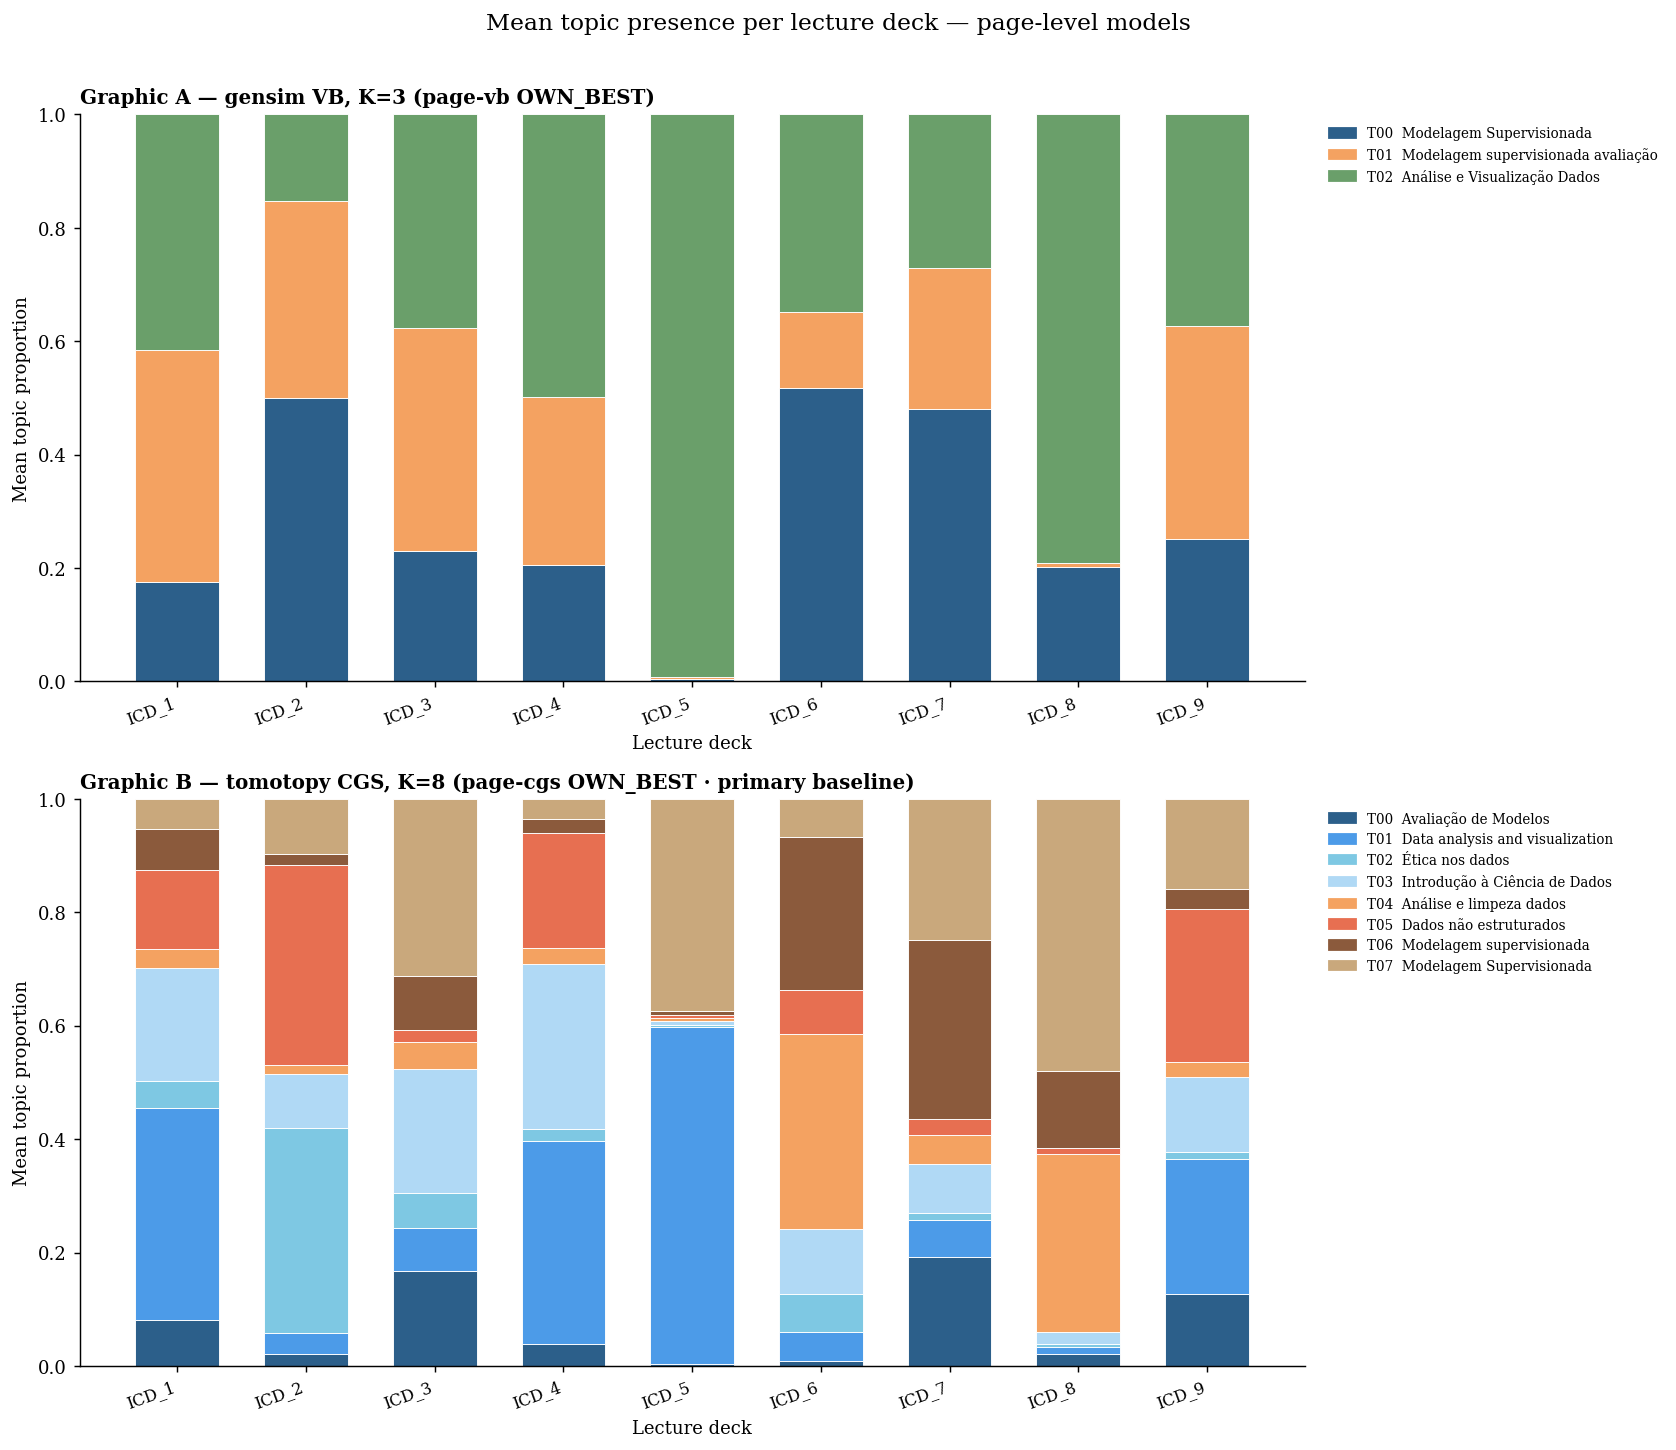

Saved to data/output/topic_deck_presence_ownbest.png


In [33]:
def _deck_mean_theta(theta, page_docs_df):
    df = page_docs_df.reset_index(drop=True).copy()
    df['_idx'] = df.index
    deck_order  = list(dict.fromkeys(df['source_file']))
    deck_labels = [_deck_label(sf) for sf in deck_order]
    deck_theta  = np.vstack([
        theta[df[df['source_file'] == sf]['_idx'].values].mean(axis=0)
        for sf in deck_order
    ])
    return deck_labels, deck_theta

deck_labels_vb,  deck_theta_vb  = _deck_mean_theta(_theta_gensim(m_page_vb,  bow1,  3), page_docs)
deck_labels_cgs, deck_theta_cgs = _deck_mean_theta(_theta_tomotopy(m_page_cgs),           page_docs)

labels_vb  = generate_topic_labels_llm(m_page_vb,  3)
labels_cgs = generate_topic_labels_llm(m_page_cgs, 8)

TOPIC_COLORS_8_ = [
    '#2C5F8A', '#4C9BE8', '#7EC8E3', '#B0D9F5',
    '#F4A261', '#E76F51', '#8B5A3C', '#C9A87C',
]

fig, axes = plt.subplots(2, 1, figsize=(13, 11), sharex=False)
fig.suptitle('Mean topic presence per lecture deck — page-level models',
             fontsize=13, y=1.01)

_cfgs = [
    dict(ax=axes[0], theta=deck_theta_vb,  labels=deck_labels_vb,  k=3,
         colors=TOPIC_COLORS_3,   topic_labels=labels_vb,
         title='Graphic A — gensim VB, K=3 (page-vb OWN_BEST)'),
    dict(ax=axes[1], theta=deck_theta_cgs, labels=deck_labels_cgs, k=8,
         colors=TOPIC_COLORS_8_,  topic_labels=labels_cgs,
         title='Graphic B — tomotopy CGS, K=8 (page-cgs OWN_BEST · primary baseline)'),
]

for cfg in _cfgs:
    ax     = cfg['ax']
    theta  = cfg['theta']
    k      = cfg['k']
    colors = cfg['colors']
    x      = np.arange(len(cfg['labels']))

    bottom = np.zeros(len(cfg['labels']))
    for t in range(k):
        ax.bar(x, theta[:, t], 0.65, bottom=bottom,
               color=colors[t], edgecolor='white', linewidth=0.5)
        bottom += theta[:, t]

    ax.set_xticks(x)
    ax.set_xticklabels(cfg['labels'], rotation=20, ha='right', fontsize=9)
    ax.set_xlabel('Lecture deck', fontsize=10)
    ax.set_ylabel('Mean topic proportion', fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_title(cfg['title'], fontsize=11, fontweight='bold', loc='left')
    handles = [mpatches.Patch(color=colors[t], label=f'T{t:02d}  {cfg["topic_labels"][t]}')
               for t in range(k)]
    ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.01, 1.0),
              fontsize=7.5, frameon=False)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, 'topic_deck_presence_ownbest.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved to data/output/topic_deck_presence_ownbest.png')

## 7. Cross-library C_v on a common estimator

`C_v` is estimator-dependent: the gensim (`CoherenceModel`) and tomotopy (`Coherence`) implementations return different scores for identical topics. The native per-library numbers in Section 2 are therefore **not** directly comparable across libraries. This section recomputes `C_v` for every page- and deck-level OWN_BEST model under a **single** estimator (gensim `CoherenceModel`) on a shared reference corpus per granularity.

The hLDA-vs-`lda-page-cgs` comparison is unaffected (both tomotopy).

In [34]:
from sklearn.model_selection import train_test_split
import gensim.corpora as _corpora
from gensim.models import LdaModel as _LdaModel, CoherenceModel as _CoherenceModel
import tomotopy as _tp

_SEED = 42
_page = build_slide_page_docs(corpus_raw)
_page = _page[_page['n_tokens'] >= MIN_TOKENS].reset_index(drop=True)
_deck = build_slide_deck_docs(corpus_raw)
_ptr, _ = train_test_split(_page, test_size=0.10, random_state=_SEED)
_ptrain  = _ptr['tokens'].tolist()
_dtr, _  = train_test_split(_deck, test_size=1, random_state=_SEED)
_dtrain  = _dtr['tokens'].tolist()
_pdict   = _corpora.Dictionary(_ptrain)
_ddict   = _corpora.Dictionary(_dtrain)

def _common_cv(topics_words, dic, texts):
    dt = set(dic.token2id)
    tw = [[w for w in ws if w in dt] for ws in topics_words]
    tw = [ws for ws in tw if len(ws) >= 2]
    return _CoherenceModel(topics=tw, texts=texts, dictionary=dic,
                           coherence='c_v', processes=1).get_coherence()

def _gensim_topics(texts, k, no_above, passes, iters):
    d = _corpora.Dictionary(texts)
    d.filter_extremes(no_below=2, no_above=no_above)
    d.compactify()
    m = _LdaModel(corpus=[d.doc2bow(t) for t in texts], id2word=d, num_topics=k,
                  passes=passes, iterations=iters, alpha=0.1, eta=0.01, random_state=_SEED)
    return [[w for w, _ in m.show_topic(i, topn=10)] for i in range(k)]

def _tomo_topics(texts, k, iters):
    m = _tp.LDAModel(k=k, alpha=0.1, eta=0.01, min_df=2, rm_top=0, seed=_SEED)
    for t in texts:
        m.add_doc(t)
    m.train(0)
    m.train(iters, workers=1)
    return [[w for w, _ in m.get_topic_words(i, top_n=10)] for i in range(k)]

rows = [
    ('page-vb  (gensim VB,  k=3)',  _common_cv(_gensim_topics(_ptrain, 3,  0.8, 20, 400), _pdict, _ptrain)),
    ('page-cgs (tomotopy CGS, k=8)', _common_cv(_tomo_topics(_ptrain,  8,  1000),          _pdict, _ptrain)),
    ('deck-vb  (gensim VB,  k=3)',  _common_cv(_gensim_topics(_dtrain, 3,  0.9, 30, 500), _ddict, _dtrain)),
    ('deck-cgs (tomotopy CGS, k=3)', _common_cv(_tomo_topics(_dtrain,  3,  2000),          _ddict, _dtrain)),
]

print('Common-estimator (gensim CoherenceModel) C_v — fair cross-library comparison:')
for name, cv in rows:
    marker = ' ← primary baseline' if 'page-cgs' in name else ''
    print(f'  {name}:  C_v = {cv:.4f}{marker}')
print()
print('Interpretation: CGS > VB under a single estimator confirms inference algorithm')
print('as the dominant factor, not estimator bias.')

Dropping 6 empty pages after tokenisation.


Common-estimator (gensim CoherenceModel) C_v — fair cross-library comparison:
  page-vb  (gensim VB,  k=3):  C_v = 0.4027
  page-cgs (tomotopy CGS, k=8):  C_v = 0.4457 ← primary baseline
  deck-vb  (gensim VB,  k=3):  C_v = 0.6041
  deck-cgs (tomotopy CGS, k=3):  C_v = 0.5717

Interpretation: CGS > VB under a single estimator confirms inference algorithm
as the dominant factor, not estimator bias.
